Version control: Monday, 2026-10-05, 14:40, America/Sao_Paulo (UTC−3)
Luis Anunciacao, PhD

# SOFT follow-up survey: data analysis

- Input: `soft.RData` from GitHub `Processing and analysis/Importable data/` (output of `DP - SOFT qualitative.ipynb`).
- Figures 1 and 2 are written to `1 - School Mental Health/`.

### Packages and data

In [1]:
# load packages; wordcloud, psych, ordinal, lme4, performance, parameters, effectsize, broom, quanteda.textstats, IRdisplay, curl and gitcreds are called with ::
pacman::p_load(tidyverse, igraph, quanteda, rainette, arsenal)

In [2]:
# arsenal defaults for the descriptive tables: no tests, M (SD) with 2 decimals, n (%) with 1 decimal; Total column when a by variable is given
tb_ctrl <- tableby.control(test = FALSE, total = TRUE, digits = 2, digits.pct = 1, numeric.stats = c("N", "meansd"), cat.stats = "countpct")

In [3]:
# DP output from GitHub (Processing and analysis/Importable data/soft.RData): df (one row per response and section) and df_original (raw open answers); private repository, token from the git credential store (gitcreds)
load(gzcon(curl::curl("https://raw.githubusercontent.com/anovabr/school_of_thinkers/main/Processing%20and%20analysis/Importable%20data/soft.RData",
                      handle = curl::new_handle() |> curl::handle_setheaders(Authorization = paste("token", gitcreds::gitcreds_get()$password)))))

### 1. Participants

In [4]:
# teacher characteristics, one row per teacher (arsenal)
df |>
  distinct(teacher_id, .keep_all = TRUE) |>
  tableby(~ age + sex + role + years_education + training + school, data = _, control = tb_ctrl, numeric.stats = c("N", "meansd", "range")) |>
  summary(text = TRUE)



|                                      | Overall (N=52) |
|:-------------------------------------|:--------------:|
|age                                   |                |
|-  N                                  |       52       |
|-  Mean (SD)                          |  39.37 (9.34)  |
|-  Range                              | 20.00 - 59.00  |
|sex                                   |                |
|-  Female                             |   40 (76.9%)   |
|-  Male                               |   11 (21.2%)   |
|-  Not estimated                      |    1 (1.9%)    |
|role                                  |                |
|-  Classroom assistant                |   7 (13.5%)    |
|-  Classroom teacher                  |   34 (65.4%)   |
|-  Coordination or management         |    5 (9.6%)    |
|-  Educational development technician |    4 (7.7%)    |
|-  Not informed                       |    2 (3.8%)    |
|years_education                       |                |
|-  Up to 1 

In [5]:
# class evaluated and responses with at least one open answer, one row per response (arsenal)
df |>
  summarise(grade = first(grade), open_answer = any(!is.na(resposta)), .by = id_resposta) |>
  tableby(~ grade + open_answer, data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                          | Overall (N=53) |
|:-------------------------|:--------------:|
|grade                     |                |
|-  Grade 1                |   12 (22.6%)   |
|-  Grade 2                |   11 (20.8%)   |
|-  Grade 3                |   10 (18.9%)   |
|-  Grade 4                |   7 (13.2%)    |
|-  Grade 5                |   9 (17.0%)    |
|-  Grade 6                |    1 (1.9%)    |
|-  Preschool (final year) |    3 (5.7%)    |
|open_answer               |                |
|-  FALSE                  |   8 (15.1%)    |
|-  TRUE                   |   45 (84.9%)   |


### 2. Corpus, word frequencies, word cloud and similitude tree

In [6]:
# corpus size: answers, words and lemmas
df |>
  filter(!is.na(resposta)) |>
  mutate(words = str_count(resposta, "\\S+")) |>
  summarise(answers = n(), words_total = sum(words), words_mdn = median(words),
            words_q1 = quantile(words, .25, names = FALSE), words_q3 = quantile(words, .75, names = FALSE),
            lemma_types = n_distinct(unlist(lemmas)), lemmas = sum(lengths(lemmas)))

answers,words_total,words_mdn,words_q1,words_q3,lemma_types,lemmas
<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>
374,7504,12,5,25,976,3575


In [7]:
# 10 most frequent lemmas
df |>
  select(lemma = lemmas, english = lemmas_en) |>
  unnest(c(lemma, english)) |>
  count(lemma, english, sort = TRUE) |>
  slice_head(n = 10)

lemma,english,n
<chr>,<chr>,<int>
aluno,student,145
bom,good,69
fazer,do,50
aula,class,49
momento,moment,47
experiencia,experience,43
sala,classroom,41
sempre,always,35
aprender,learn,31


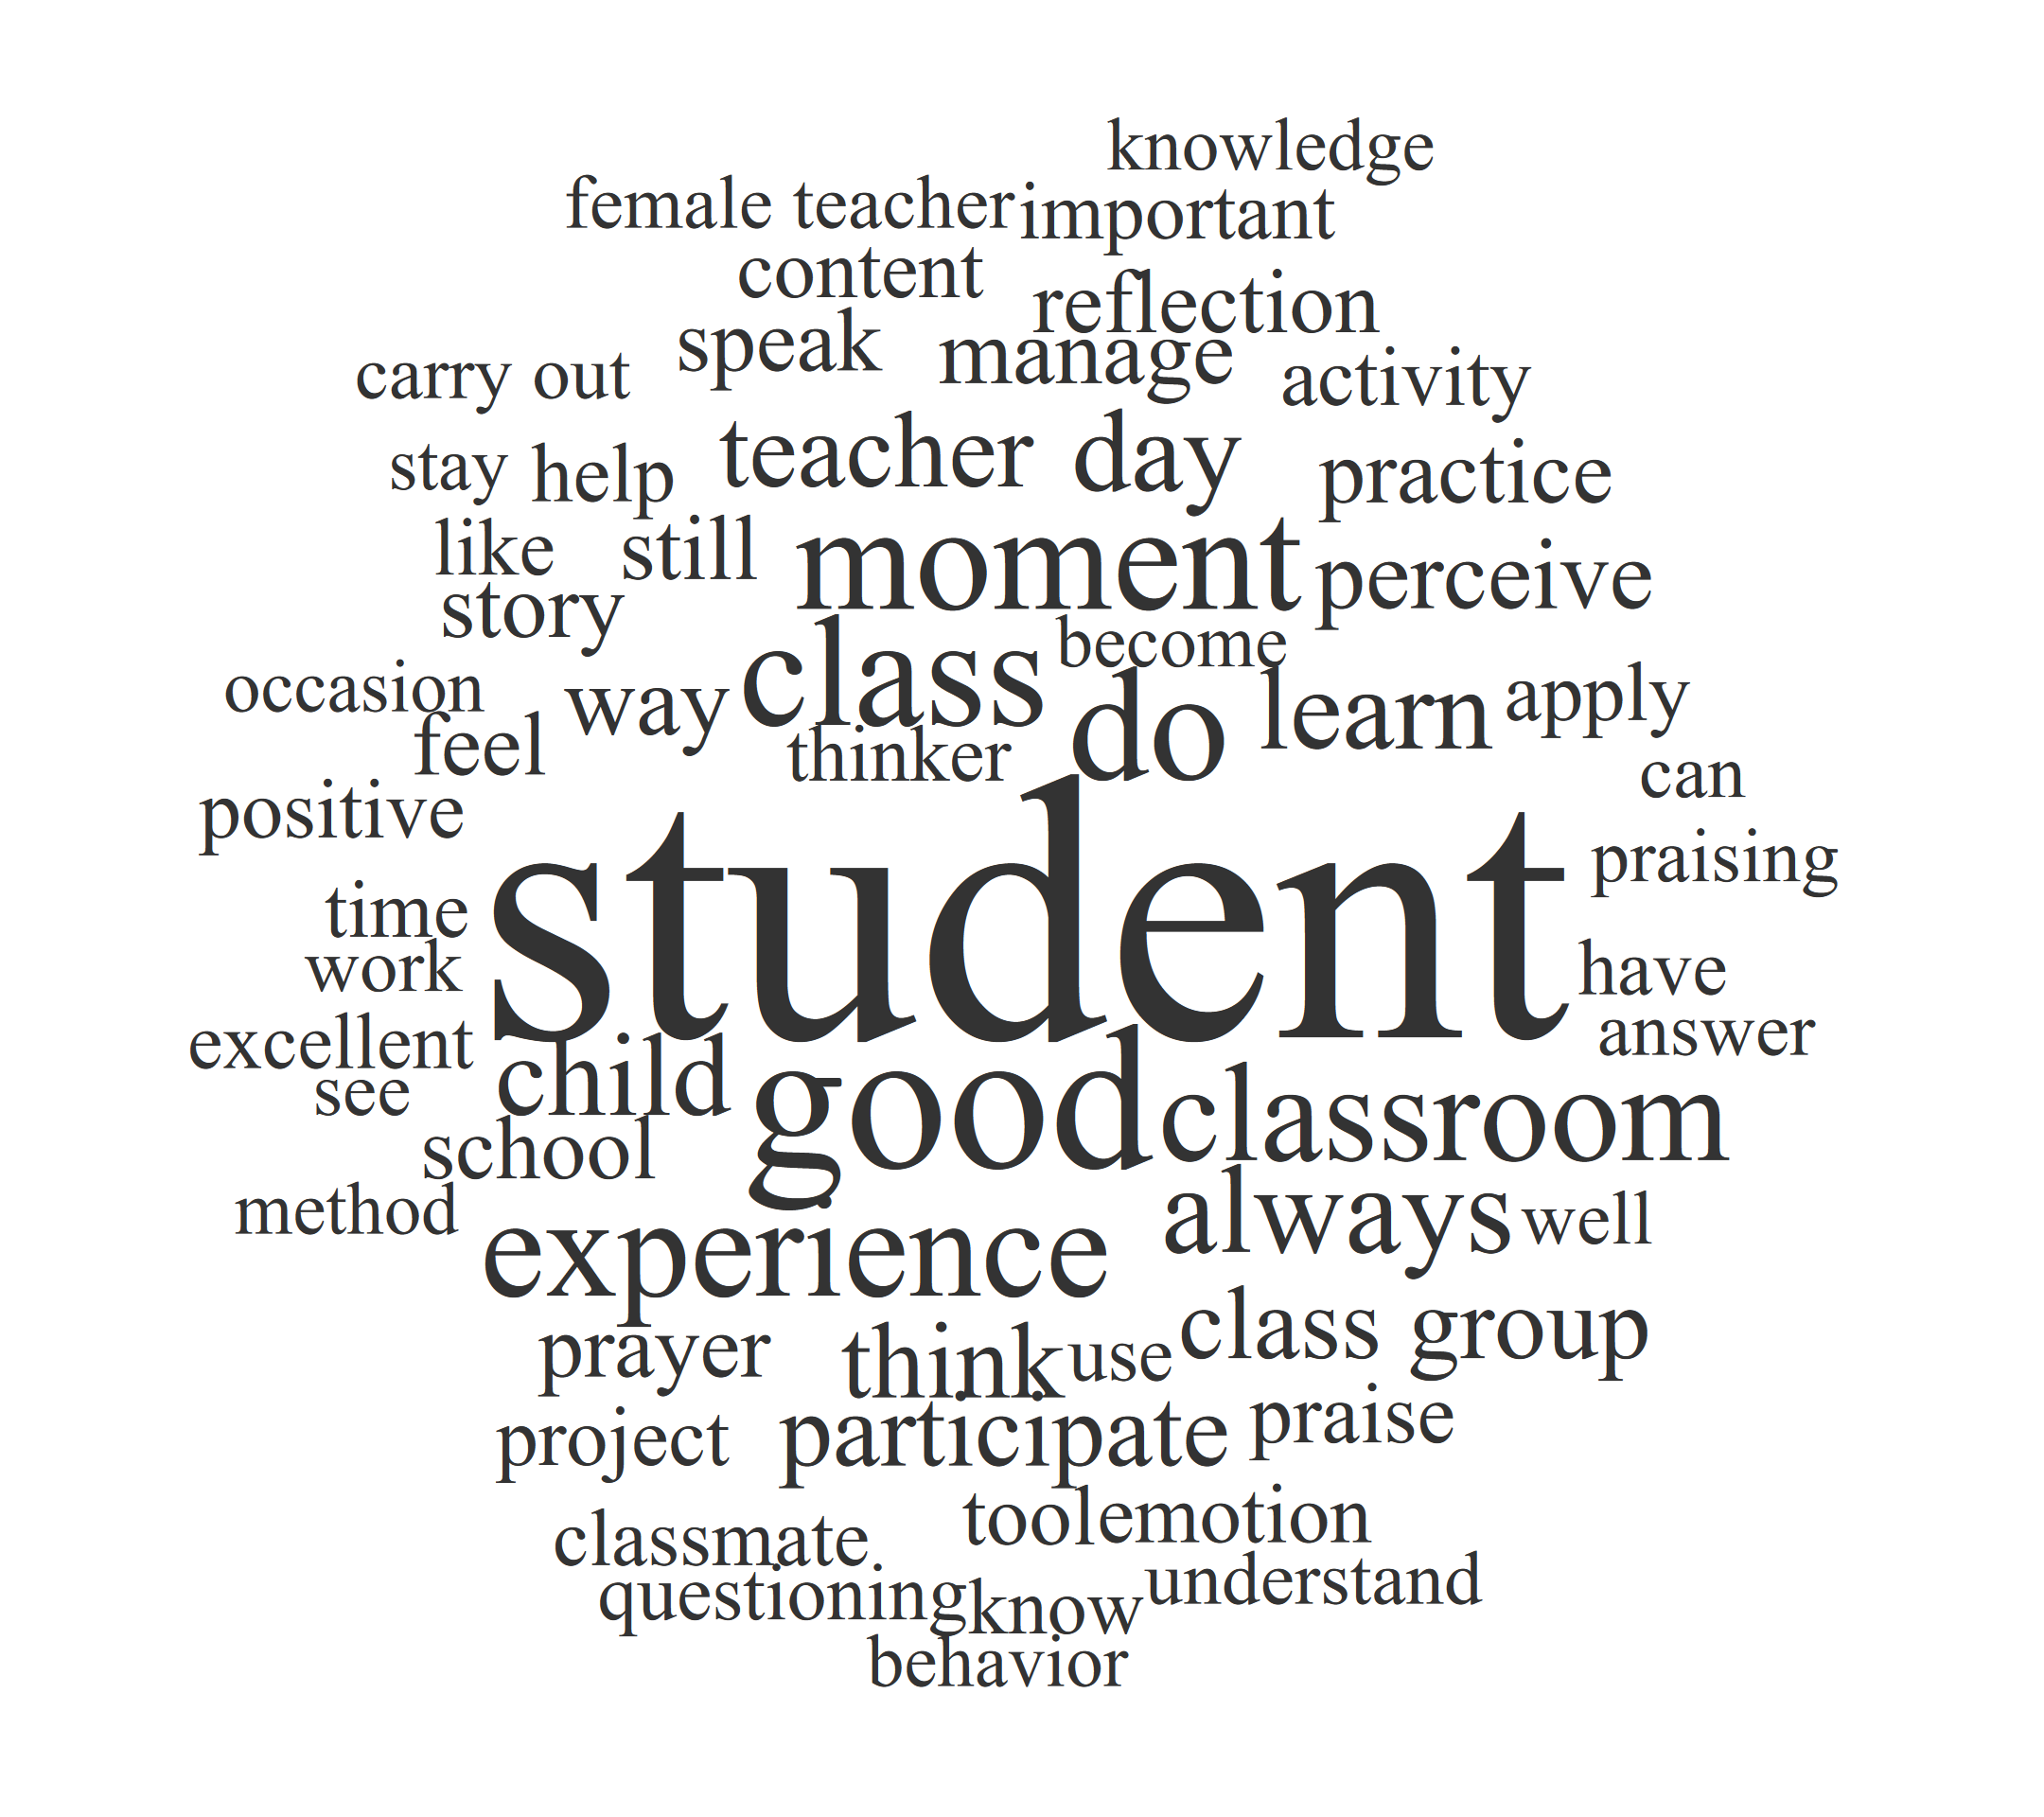

In [8]:
# word cloud: 60 most frequent lemmas (English), size proportional to frequency; seed 2026; drawn on a PNG device (submission figure) and shown inline
png("1 - School Mental Health/Figure_1.png", width = 3.6, height = 3.2, units = "in", res = 600, type = "cairo")
par(mar = c(0, 0, 0, 0))
set.seed(2026)
df |>
  select(lemma = lemmas, english = lemmas_en) |>
  unnest(c(lemma, english)) |>
  count(lemma, english, sort = TRUE) |>
  (\(f) wordcloud::wordcloud(f$english, f$n, max.words = 60, min.freq = 1, random.order = FALSE,
                             rot.per = 0, colors = "grey20", family = "serif"))()
invisible(dev.off())
IRdisplay::display_png(file = "1 - School Mental Health/Figure_1.png")

In [9]:
# similitude tree: lemmas occurring >= 10 times; edge weight = answers containing both lemmas; maximum spanning tree
g <- df |>
  mutate(answer = row_number()) |>
  select(answer, lemma = lemmas, english = lemmas_en) |>
  unnest(c(lemma, english)) |>                                                             # one row per lemma occurrence
  add_count(lemma, name = "freq") |>                                                       # corpus frequency of the lemma
  filter(freq >= 10) |>
  (\(d) d |>
     distinct(answer, lemma) |>                                                             # presence per answer
     (\(a) inner_join(a, a, by = "answer", relationship = "many-to-many"))() |>
     filter(lemma.x < lemma.y) |>                                                          # each pair once
     count(lemma.x, lemma.y, name = "weight") |>                                           # cooccurrence
     graph_from_data_frame(directed = FALSE) |>
     (\(g) mst(g, weights = max(E(g)$weight) + 1 - E(g)$weight))() |>                       # maximum spanning tree = minimum tree on reversed weights
     (\(g) set_vertex_attr(g, "english", value = deframe(distinct(d, lemma, english))[V(g)$name]))() |>
     (\(g) set_vertex_attr(g, "freq", value = deframe(distinct(d, lemma, freq))[V(g)$name]))())()
vcount(g)

[1] 82

In [10]:
# 10 strongest edges of the tree
igraph::as_data_frame(g, what = "edges") |>
  slice_max(weight, n = 10, with_ties = FALSE) |>
  mutate(across(c(from, to), \(x) V(g)[x]$english))

from,to,weight
<chr>,<chr>,<int>
student,class,21
student,good,21
student,moment,20
student,participate,20
student,teacher,20
student,experience,19
student,classroom,19
student,learn,18
student,do,18


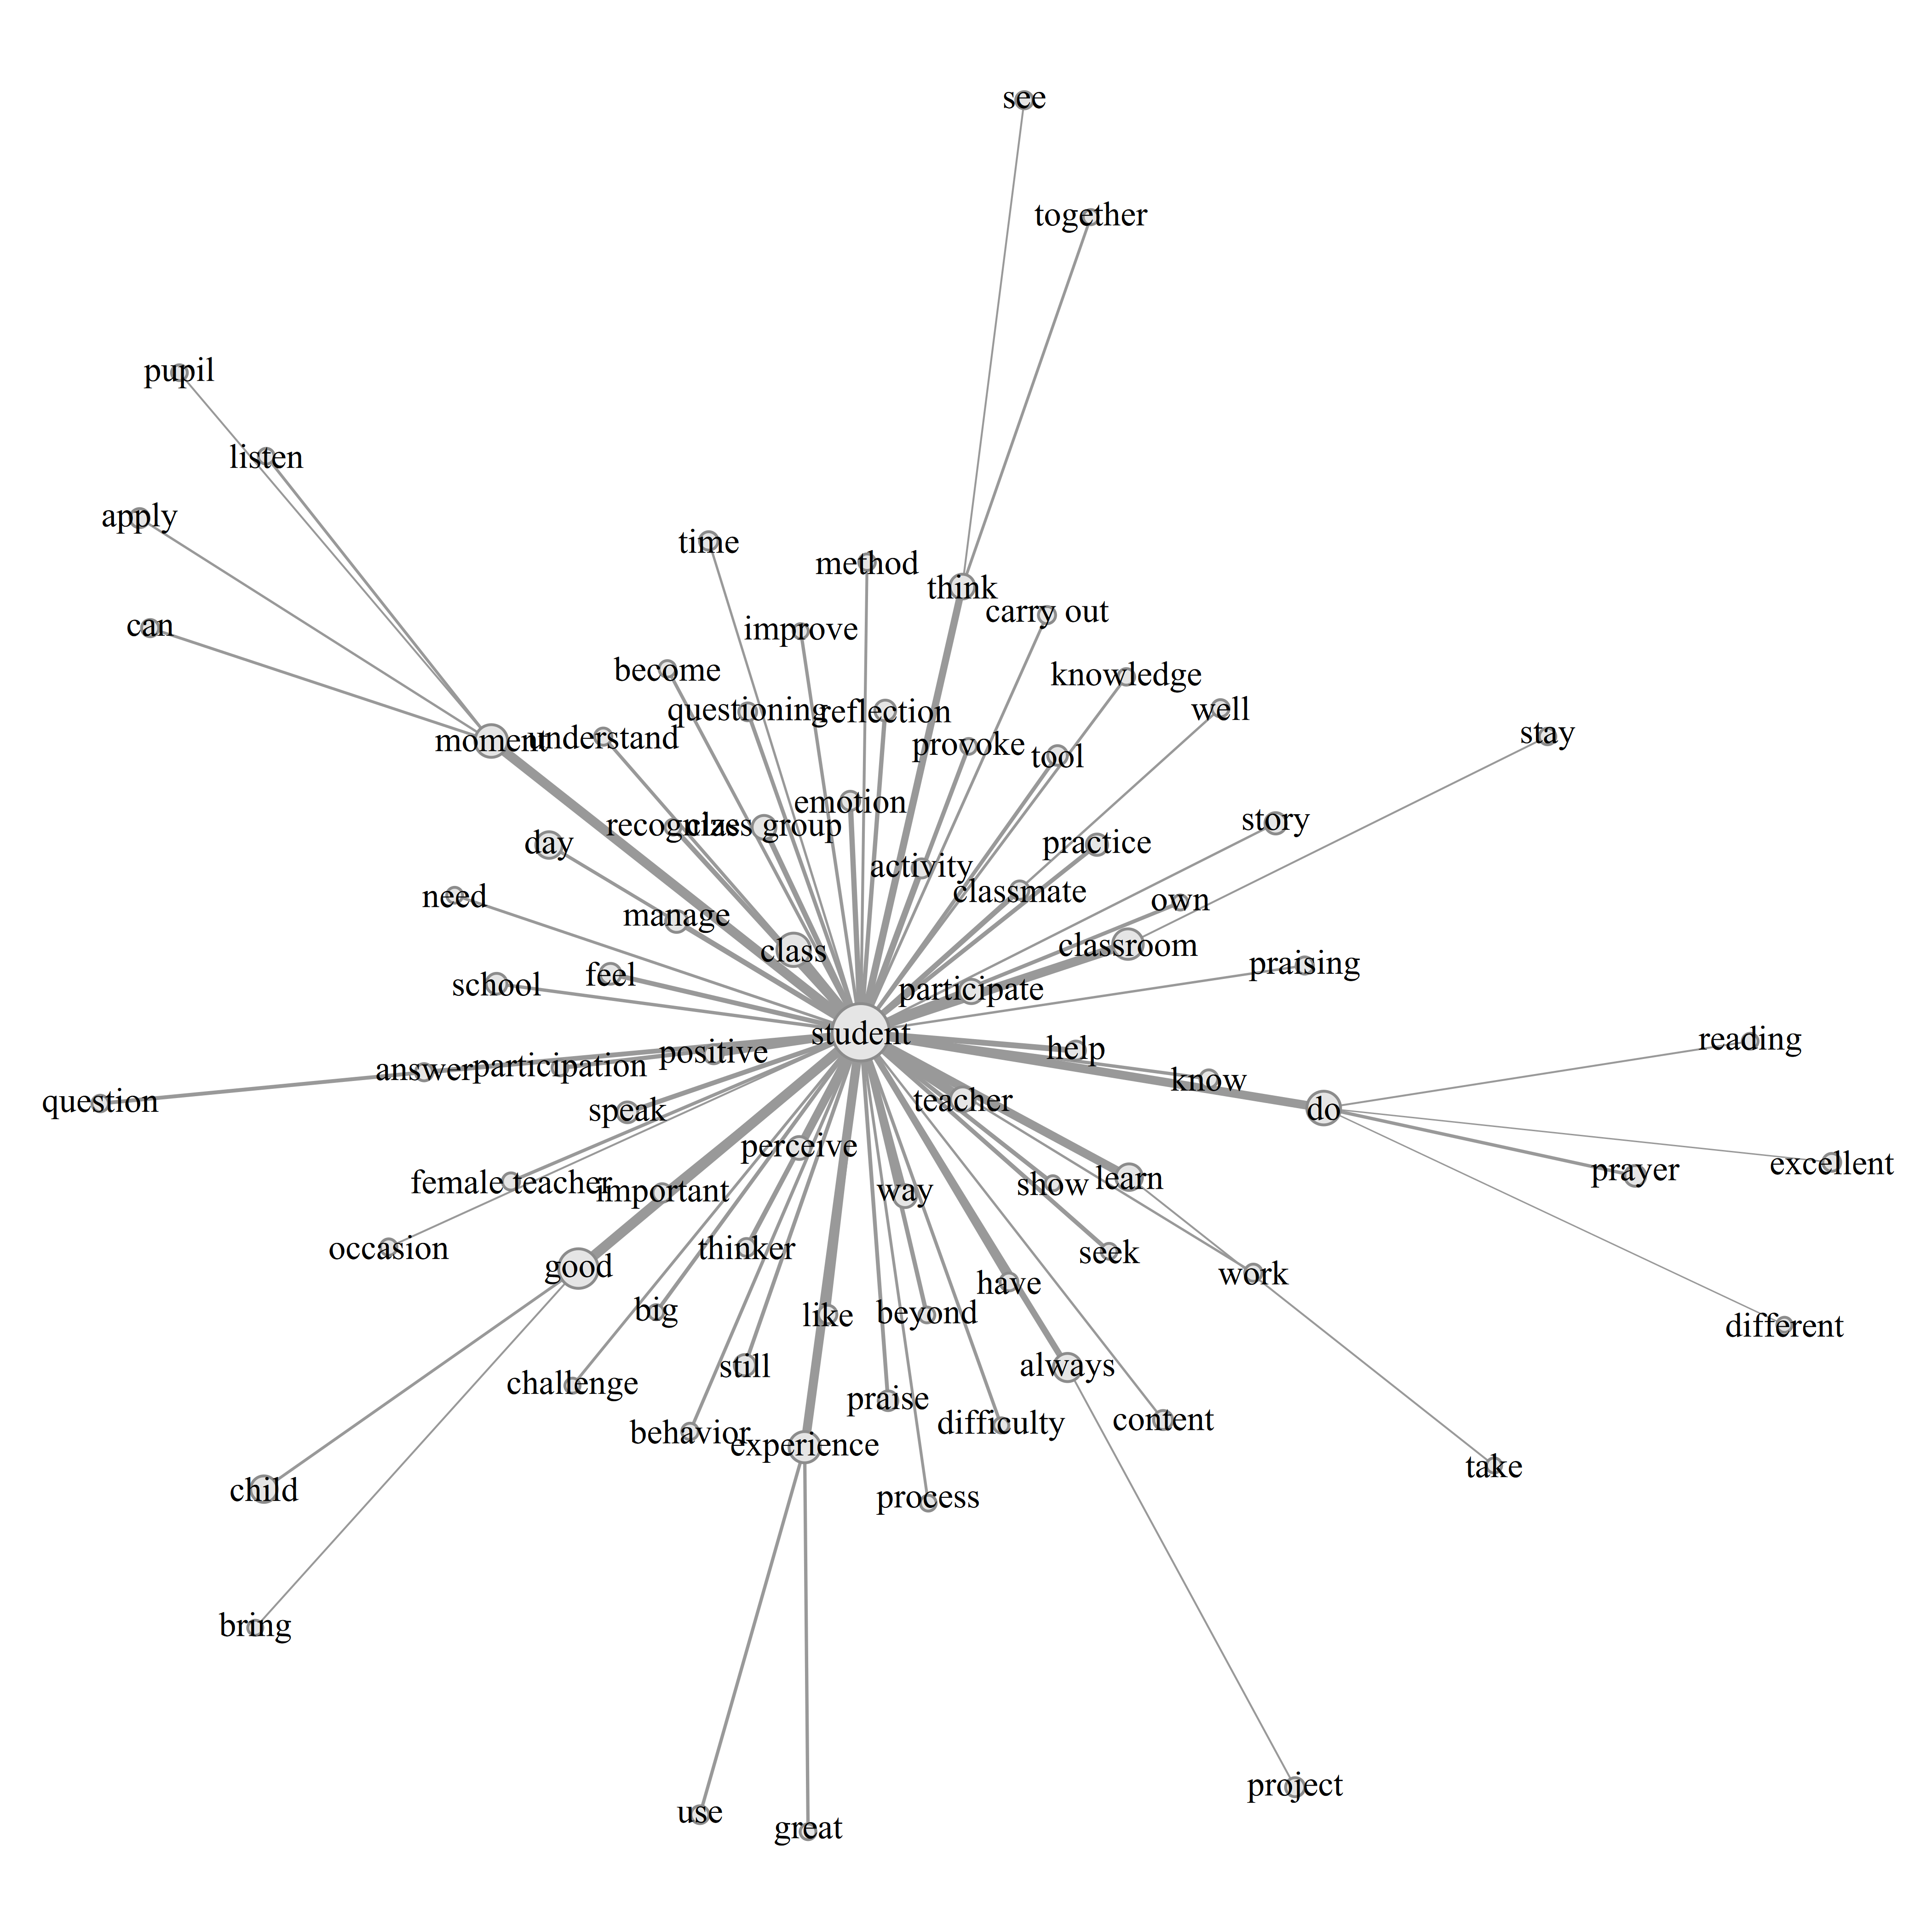

In [11]:
# similitude tree plot; Fruchterman-Reingold layout, seed 2026; drawn on a PNG device (submission figure) and shown inline
png("1 - School Mental Health/Figure_2.png", width = 7, height = 7, units = "in", res = 600, type = "cairo")
par(mar = c(0, 0, 0, 0))
set.seed(2026)
plot(g, layout = layout_with_fr(g, niter = 3000), vertex.label = V(g)$english, vertex.color = "grey90", vertex.frame.color = "grey55",
     vertex.label.color = "black", vertex.label.family = "serif", vertex.label.cex = 0.75,
     vertex.size = sqrt(V(g)$freq) * 0.55, edge.width = E(g)$weight / 6, edge.color = "grey60")
invisible(dev.off())
IRdisplay::display_png(file = "1 - School Mental Health/Figure_2.png")

### 3. Directed content analysis: mood and implementation by tool

In [12]:
# mood and implementation codes by tool, column % (arsenal); Total = all tools
df |>
  filter(!is.na(mood)) |>
  mutate(tool = fct_drop(tool)) |>
  tableby(tool ~ mood_group + implementation, data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                     | Provoking/Questioning Teacher (N=43) | Praising Teacher (N=42) | Challenging/Thinking Teacher (N=36) | Thinkers' Prayer/Phrase (N=37) | Thinkers' Storytellers (N=34) | Circle/Double U (N=39) | Thinkers' Minute Quiz (N=37) | Welcoming Troop/Emotion Firefighters (N=36) | Total (N=304) |
|:--------------------|:------------------------------------:|:-----------------------:|:-----------------------------------:|:------------------------------:|:-----------------------------:|:----------------------:|:----------------------------:|:-------------------------------------------:|:-------------:|
|mood_group           |                                      |                         |                                     |                                |                               |                        |                              |                                             |               |
|-  descriptive       |              6 (14.0%)               |      

In [13]:
# reasons for easy and hard implementation (arsenal frequency list)
df |>
  filter(!is.na(reason)) |>
  freqlist(~ implementation + reason, data = _) |>
  summary()



|implementation |reason          | Freq| Cumulative Freq| Percent| Cumulative Percent|
|:--------------|:---------------|----:|---------------:|-------:|------------------:|
|easy           |routine         |   30|              30|   28.04|              28.04|
|               |simple          |   18|              48|   16.82|              44.86|
|               |uptake          |    6|              54|    5.61|              50.47|
|hard           |fit             |    6|              60|    5.61|              56.07|
|               |general         |    8|              68|    7.48|              63.55|
|               |not_implemented |   12|              80|   11.21|              74.77|
|               |space           |    3|              83|    2.80|              77.57|
|               |students        |   14|              97|   13.08|              90.65|
|               |time            |    6|             103|    5.61|              96.26|
|               |understanding   |    4| 

In [14]:
# teachers with coded answers and with >= 1 hard answer
df |>
  filter(!is.na(mood)) |>
  summarise(teachers = n_distinct(teacher_id), teachers_with_hard = n_distinct(teacher_id[implementation == "hard"]))

teachers,teachers_with_hard
<int>,<int>
43,23


In [15]:
# 6 most frequent lemmas (English) per tool
df |>
  filter(!is.na(mood)) |>
  select(tool, english = lemmas_en) |>
  unnest(english) |>
  count(tool, english) |>
  arrange(tool, desc(n)) |>
  slice_head(n = 6, by = tool) |>
  summarise(top_lemmas = str_c(english, " (", n, ")", collapse = ", "), .by = tool) |>
  as.data.frame()

tool,top_lemmas
<fct>,<chr>
Provoking/Questioning Teacher,"student (30), good (18), experience (14), think (10), moment (9), questioning (9)"
Praising Teacher,"student (25), praise (15), good (11), praising (11), experience (7), recognize (7)"
Challenging/Thinking Teacher,"student (20), learn (8), think (6), class (5), experience (5), good (5)"
Thinkers' Prayer/Phrase,"prayer (12), do (11), class (9), reflection (9), student (9), moment (8)"
Thinkers' Storytellers,"story (20), good (9), student (8), author (6), tell (6), bring (5)"
Circle/Double U,"student (13), classroom (11), always (8), class group (7), class (6), stay (6)"
Thinkers' Minute Quiz,"student (9), apply (6), class (6), learn (6), minute (6), quiz (6)"
Welcoming Troop/Emotion Firefighters,"student (11), emotion (10), good (8), firefighter (7), school (7), behavior (5)"


### 4. Closed ratings: program and tools

In [16]:
# overall experience and support ratings, one row per response: n, M (SD) and distribution of the 1 to 5 codes (arsenal)
df |>
  distinct(id_resposta, .keep_all = TRUE) |>
  tableby(~ overall + support_school + support_coordinator + factor(overall) + factor(support_school) + factor(support_coordinator) + support_need,
          data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                            | Overall (N=53) |
|:---------------------------|:--------------:|
|overall                     |                |
|-  N                        |       53       |
|-  Mean (SD)                |  4.08 (0.55)   |
|support_school              |                |
|-  N                        |       53       |
|-  Mean (SD)                |  4.17 (0.89)   |
|support_coordinator         |                |
|-  N                        |       53       |
|-  Mean (SD)                |  4.30 (0.70)   |
|factor(overall)             |                |
|-  3                        |   6 (11.3%)    |
|-  4                        |   37 (69.8%)   |
|-  5                        |   10 (18.9%)   |
|factor(support_school)      |                |
|-  1                        |    1 (1.9%)    |
|-  2                        |    2 (3.8%)    |
|-  3                        |    5 (9.4%)    |
|-  4                        |   24 (45.3%)   |
|-  5                        |   21 (3

In [17]:
# frequency of use and ease of application by tool, one row per response and tool: M (SD) and % top two (1 = top two) (arsenal)
df |>
  filter(!is.na(ease)) |>
  distinct(id_resposta, sec, .keep_all = TRUE) |>
  mutate(tool = fct_drop(tool)) |>
  tableby(tool ~ freq + ease + factor(freq_top2) + factor(ease_top2), data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                  | Provoking/Questioning Teacher (N=53) | Praising Teacher (N=53) | Challenging/Thinking Teacher (N=53) | Thinkers' Prayer/Phrase (N=53) | Thinkers' Storytellers (N=53) | Circle/Double U (N=53) | Thinkers' Minute Quiz (N=53) | Welcoming Troop/Emotion Firefighters (N=53) | Total (N=424) |
|:-----------------|:------------------------------------:|:-----------------------:|:-----------------------------------:|:------------------------------:|:-----------------------------:|:----------------------:|:----------------------------:|:-------------------------------------------:|:-------------:|
|freq              |                                      |                         |                                     |                                |                               |                        |                              |                                             |               |
|-  N              |                  53                  |           53     

### 5. Integration: codes and ratings of the same teacher for the same tool
- Mixed models: answers nested in teachers; random intercept per teacher; adaptive Gauss-Hermite quadrature, 10 points.
- OR > 1 = higher rating than the reference code (easy; positive); Wald 95% CI.

In [18]:
# joint display, implementation codes: ease M (SD), % ease top two and % frequency top two (1 = top two) (arsenal)
df |>
  filter(!is.na(mood)) |>
  tableby(implementation ~ ease + factor(ease_top2) + factor(freq_top2), data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                  | easy (N=54) | hard (N=53) | not stated (N=197) | Total (N=304) |
|:-----------------|:-----------:|:-----------:|:------------------:|:-------------:|
|ease              |             |             |                    |               |
|-  N              |     54      |     53      |        197         |      304      |
|-  Mean (SD)      | 4.15 (0.68) | 2.98 (0.89) |    4.05 (0.68)     |  3.88 (0.83)  |
|factor(ease_top2) |             |             |                    |               |
|-  0              |  9 (16.7%)  | 41 (77.4%)  |     32 (16.2%)     |  82 (27.0%)   |
|-  1              | 45 (83.3%)  | 12 (22.6%)  |    165 (83.8%)     |  222 (73.0%)  |
|factor(freq_top2) |             |             |                    |               |
|-  0              |  8 (14.8%)  | 27 (50.9%)  |     30 (15.2%)     |  65 (21.4%)   |
|-  1              | 46 (85.2%)  | 26 (49.1%)  |    167 (84.8%)     |  239 (78.6%)  |


In [19]:
# joint display, mood codes (negative and mixed pooled): ease M (SD), % ease top two and % frequency top two (1 = top two) (arsenal)
df |>
  filter(!is.na(mood)) |>
  tableby(mood_group ~ ease + factor(ease_top2) + factor(freq_top2), data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                  | descriptive (N=91) | negative or mixed (N=16) | positive (N=197) | Total (N=304) |
|:-----------------|:------------------:|:------------------------:|:----------------:|:-------------:|
|ease              |                    |                          |                  |               |
|-  N              |         91         |            16            |       197        |      304      |
|-  Mean (SD)      |    3.44 (0.92)     |       2.94 (0.57)        |   4.16 (0.64)    |  3.88 (0.83)  |
|factor(ease_top2) |                    |                          |                  |               |
|-  0              |     46 (50.5%)     |        14 (87.5%)        |    22 (11.2%)    |  82 (27.0%)   |
|-  1              |     45 (49.5%)     |        2 (12.5%)         |   175 (88.8%)    |  222 (73.0%)  |
|factor(freq_top2) |                    |                          |                  |               |
|-  0              |     36 (39.6%)     |        5 (31.2%)    

In [20]:
# unadjusted association: Pearson chi-square, Cramer's V (effectsize, no bias correction), smallest expected count, Fisher exact p
df |>
  filter(!is.na(mood)) |>
  (\(d) tribble(~test, ~x, ~y,
                "implementation x ease top two", "implementation", "ease_top2",
                "mood x ease top two", "mood_group", "ease_top2",
                "implementation x frequency top two", "implementation", "freq_top2",
                "mood x frequency top two", "mood_group", "freq_top2") |>
     mutate(res = map2(x, y, \(x, y) table(d[[x]], d[[y]]) |>
                         (\(t) suppressWarnings(chisq.test(t)) |>
                            (\(ct) tibble(chi2 = unname(ct$statistic), df = unname(ct$parameter), p = ct$p.value,
                                          V = effectsize::cramers_v(t, adjust = FALSE)$Cramers_v,
                                          min_expected = min(ct$expected), fisher_p = fisher.test(t)$p.value))())())))() |>
  unnest(res) |>
  select(-x, -y) |>
  mutate(across(where(is.double), \(x) signif(x, 3)))

test,chi2,df,p,V,min_expected,fisher_p
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
implementation x ease top two,82.7,2,1.08e-18,0.522,14.30,5.64e-17
mood x ease top two,80.4,2,3.44e-18,0.514,4.32,3.37e-18
implementation x frequency top two,33.4,2,5.66e-08,0.331,11.30,4.60e-07
mood x frequency top two,28.7,2,5.76e-07,0.307,3.42,6.82e-07


In [21]:
# mixed models: ordinal ease (clmm) and frequency top two (logistic glmer) on the codes; tool-adjusted versions
mlm <- df |>
  filter(!is.na(mood)) |>
  mutate(ease = factor(ease, levels = 1:5, ordered = TRUE), teacher = factor(teacher_id), tool = fct_drop(tool),
         implementation = fct_relevel(implementation, "easy"), mood = fct_relevel(mood_group, "positive")) |>
  (\(d) list(data = d,
             null = ordinal::clmm(ease ~ 1 + (1 | teacher), data = d, nAGQ = 10),
             implementation = ordinal::clmm(ease ~ implementation + (1 | teacher), data = d, nAGQ = 10),
             implementation_tool = ordinal::clmm(ease ~ implementation + tool + (1 | teacher), data = d, nAGQ = 10),
             mood = ordinal::clmm(ease ~ mood + (1 | teacher), data = d, nAGQ = 10),
             mood_tool = ordinal::clmm(ease ~ mood + tool + (1 | teacher), data = d, nAGQ = 10),
             freq_implementation = lme4::glmer(freq_top2 ~ implementation + (1 | teacher), data = d, family = binomial, nAGQ = 10),
             freq_mood = lme4::glmer(freq_top2 ~ mood + (1 | teacher), data = d, family = binomial, nAGQ = 10)))()

In [22]:
# answers, teachers and intraclass correlation of the ease rating (latent scale, null model)
tibble(answers = nrow(mlm$data), teachers = nlevels(mlm$data$teacher),
       icc_latent = performance::icc(mlm$null)$ICC_adjusted)

answers,teachers,icc_latent
<int>,<int>,<dbl>
304,43,0.3220036


In [23]:
# odds ratios of the codes, Wald 95% CI
list(`ease ~ implementation` = mlm$implementation, `ease ~ implementation + tool` = mlm$implementation_tool,
     `ease ~ mood` = mlm$mood, `ease ~ mood + tool` = mlm$mood_tool,
     `frequency top two ~ implementation` = mlm$freq_implementation, `frequency top two ~ mood` = mlm$freq_mood) |>
  imap(\(m, model) parameters::model_parameters(m, exponentiate = TRUE, ci_method = "wald", effects = "fixed") |>
         as_tibble() |>
         filter(str_detect(Parameter, "^(implementation|mood)")) |>
         transmute(model, term = Parameter, OR = round(Coefficient, 3), lower = round(CI_low, 3), upper = round(CI_high, 3), p = signif(p, 3))) |>
  list_rbind() |>
  as.data.frame()

model,term,OR,lower,upper,p
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
ease ~ implementation,implementationhard,0.022,0.008,0.061,1.66e-13
ease ~ implementation,implementationnot stated,0.648,0.326,1.291,2.17e-01
ease ~ implementation + tool,implementationhard,0.023,0.008,0.066,1.53e-12
ease ~ implementation + tool,implementationnot stated,0.588,0.286,1.209,1.49e-01
ease ~ mood,mooddescriptive,0.129,0.069,0.241,1.27e-10
ease ~ mood,moodnegative or mixed,0.036,0.012,0.107,2.29e-09
ease ~ mood + tool,mooddescriptive,0.147,0.077,0.281,6.65e-09
ease ~ mood + tool,moodnegative or mixed,0.038,0.012,0.116,9.18e-09
frequency top two ~ implementation,implementationhard,0.152,0.056,0.416,2.43e-04


In [24]:
# likelihood ratio tests of the codes against the null model
bind_rows(implementation = anova(mlm$null, mlm$implementation) |> as_tibble() |> slice(2),   # anova.clmm evaluates the model names, so no map()
          mood = anova(mlm$null, mlm$mood) |> as_tibble() |> slice(2),
          .id = "code") |>
  select(code, LR.stat, df, p = `Pr(>Chisq)`)

code,LR.stat,df,p
<chr>,<dbl>,<dbl>,<dbl>
implementation,84.36673,2,4.786272e-19
mood,64.36059,2,1.057489e-14


In [25]:
# Spearman correlations, teacher level: share of positive or hard answers vs overall experience
df |>
  filter(!is.na(mood)) |>
  summarise(positive = mean(mood == "positive"), hard = mean(implementation == "hard"), overall = first(overall), .by = teacher_id) |>
  (\(d) c("positive", "hard") |>
     map(\(v) cor.test(d[[v]], d$overall, method = "spearman", exact = FALSE) |> broom::tidy() |> mutate(test = str_c("teacher: ", v, " x overall"), n = nrow(d))))() |>
  list_rbind() |>
  select(test, rho = estimate, p = p.value, n)

test,rho,p,n
<chr>,<dbl>,<dbl>,<int>
teacher: positive x overall,0.4068891,0.006773258,43
teacher: hard x overall,-0.2721463,0.077481800,43


In [26]:
# Spearman correlations, tool level (n = 8): share of positive or hard answers vs mean ease
df |>
  filter(!is.na(mood)) |>
  summarise(positive = mean(mood == "positive"), hard = mean(implementation == "hard"), ease = mean(ease), .by = tool) |>
  (\(d) c("positive", "hard") |>
     map(\(v) cor.test(d[[v]], d$ease, method = "spearman") |> broom::tidy() |> mutate(test = str_c("tool: ", v, " x ease"), n = nrow(d))))() |>
  list_rbind() |>
  select(test, rho = estimate, p = p.value, n)

test,rho,p,n
<chr>,<dbl>,<dbl>,<int>
tool: positive x ease,0.9047619,0.004563492,8
tool: hard x ease,-0.9047619,0.004563492,8


### 6. LeIA sentiment by program, school and tool (compound; positive >= 0.05, negative <= -0.05)

In [27]:
# LeIA compound by school: n, M (SD), median and % positive, neutral, negative (arsenal); Total = all open answers
df |>
  filter(!is.na(resposta)) |>
  tableby(Escola ~ sentiment + leia_class, data = _, control = tb_ctrl, numeric.stats = c("N", "meansd", "median")) |>
  summary(text = TRUE)



|             | Futuro Brilhante (N=155) | Marton Lucca (N=219) | Total (N=374) |
|:------------|:------------------------:|:--------------------:|:-------------:|
|sentiment    |                          |                      |               |
|-  N         |           155            |         219          |      374      |
|-  Mean (SD) |       0.16 (0.41)        |     0.23 (0.40)      |  0.20 (0.40)  |
|-  Median    |           0.08           |         0.27         |     0.23      |
|leia_class   |                          |                      |               |
|-  negative  |        38 (24.5%)        |      45 (20.5%)      |  83 (22.2%)   |
|-  neutral   |        37 (23.9%)        |      48 (21.9%)      |  85 (22.7%)   |
|-  positive  |        80 (51.6%)        |     126 (57.5%)      |  206 (55.1%)  |


In [28]:
# LeIA compound by section: tools II to IX, pedagogical support (X) and final testimonials (XII) (arsenal); Total = all open answers
df |>
  filter(!is.na(resposta)) |>
  mutate(tool = fct_drop(tool)) |>
  tableby(tool ~ sentiment + leia_class, data = _, control = tb_ctrl, numeric.stats = c("N", "meansd", "median")) |>
  summary(text = TRUE)



|             | Provoking/Questioning Teacher (N=43) | Praising Teacher (N=42) | Challenging/Thinking Teacher (N=36) | Thinkers' Prayer/Phrase (N=37) | Thinkers' Storytellers (N=34) | Circle/Double U (N=39) | Thinkers' Minute Quiz (N=37) | Welcoming Troop/Emotion Firefighters (N=36) | Pedagogical support (X) (N=12) | Final testimonials (XII) (N=58) | Total (N=374) |
|:------------|:------------------------------------:|:-----------------------:|:-----------------------------------:|:------------------------------:|:-----------------------------:|:----------------------:|:----------------------------:|:-------------------------------------------:|:------------------------------:|:-------------------------------:|:-------------:|
|sentiment    |                                      |                         |                                     |                                |                               |                        |                              |                     

### 7. LeIA sentiment versus coded mood (mixed excluded)

In [29]:
# LeIA category (negative <= -0.05 < neutral < 0.05 <= positive) vs coded mood: crosstab, agreement, Cohen's kappa
df |>
  filter(!is.na(mood), mood != "mixed") |>
  mutate(leia = as.character(leia_class),
         coded = case_match(mood, "descriptive" ~ "neutral", .default = mood)) |>
  (\(d) list(table = count(d, leia, coded) |> pivot_wider(names_from = coded, values_from = n, values_fill = 0) |> as.data.frame(),
             agreement = mean(d$leia == d$coded),
             kappa = psych::cohen.kappa(as.matrix(select(d, leia, coded)))$kappa,                # psych needs a matrix of ratings
             n = nrow(d)))()

leia,negative,neutral,positive
<chr>,<int>,<int>,<int>
negative,4,30,26
neutral,1,28,34
positive,0,33,137


### 8. Mood by implementation; reasons by tool

In [30]:
# mood by implementation, counts and column % (arsenal)
df |>
  filter(!is.na(mood)) |>
  tableby(implementation ~ mood, data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|               | easy (N=54) | hard (N=53) | not stated (N=197) | Total (N=304) |
|:--------------|:-----------:|:-----------:|:------------------:|:-------------:|
|mood           |             |             |                    |               |
|-  descriptive | 22 (40.7%)  | 38 (71.7%)  |     31 (15.7%)     |  91 (29.9%)   |
|-  mixed       |  0 (0.0%)   | 11 (20.8%)  |      0 (0.0%)      |   11 (3.6%)   |
|-  negative    |  0 (0.0%)   |  4 (7.5%)   |      1 (0.5%)      |   5 (1.6%)    |
|-  positive    | 32 (59.3%)  |  0 (0.0%)   |    165 (83.8%)     |  197 (64.8%)  |


In [31]:
# reasons for easy and hard implementation by tool, counts and column % (arsenal)
df |>
  filter(!is.na(reason)) |>
  mutate(tool = fct_drop(tool)) |>
  tableby(tool ~ reason, data = _, control = tb_ctrl) |>
  summary(text = TRUE)



|                   | Provoking/Questioning Teacher (N=12) | Praising Teacher (N=10) | Challenging/Thinking Teacher (N=9) | Thinkers' Prayer/Phrase (N=13) | Thinkers' Storytellers (N=10) | Circle/Double U (N=23) | Thinkers' Minute Quiz (N=17) | Welcoming Troop/Emotion Firefighters (N=13) | Total (N=107) |
|:------------------|:------------------------------------:|:-----------------------:|:----------------------------------:|:------------------------------:|:-----------------------------:|:----------------------:|:----------------------------:|:-------------------------------------------:|:-------------:|
|reason             |                                      |                         |                                    |                                |                               |                        |                              |                                             |               |
|-  fit             |               0 (0.0%)               |        0 (0.0%) 

### 9. Keyness: characteristic lemmas of each tool (chi-square, target tool vs the other seven)

In [32]:
# 6 most characteristic lemmas per tool, >= 2 occurrences in the target tool
df |>
  filter(!is.na(mood)) |>
  (\(d) as.tokens(set_names(d$lemmas_en, str_c("a", seq_len(nrow(d))))) |>
     dfm(tolower = FALSE) |>
     dfm_group(groups = as.character(d$tool)))() |>
  (\(kw) docnames(kw) |>
     map(\(s) quanteda.textstats::textstat_keyness(kw, target = s, measure = "chi2") |>
           filter(n_target >= 2) |>
           slice_head(n = 6) |>
           transmute(tool = s, lemma = feature, chi2 = round(chi2, 1), p = signif(p, 2), n_target)))() |>
  list_rbind() |>
  as.data.frame()

tool,lemma,chi2,p,n_target
<chr>,<chr>,<dbl>,<dbl>,<dbl>
Challenging/Thinking Teacher,go,10.7,1.1e-03,3
Challenging/Thinking Teacher,well,9.9,1.6e-03,5
Challenging/Thinking Teacher,capable,8.6,3.3e-03,4
Challenging/Thinking Teacher,apply (I),8.3,4.0e-03,2
Challenging/Thinking Teacher,challenged,8.3,4.0e-03,2
Challenging/Thinking Teacher,deepen,8.3,4.0e-03,2
Circle/Double U,format,30.5,3.4e-08,5
Circle/Double U,organization,23.9,9.9e-07,5
Circle/Double U,circle,15.3,9.2e-05,3


### 10. Word clouds by tool (25 most frequent lemmas)

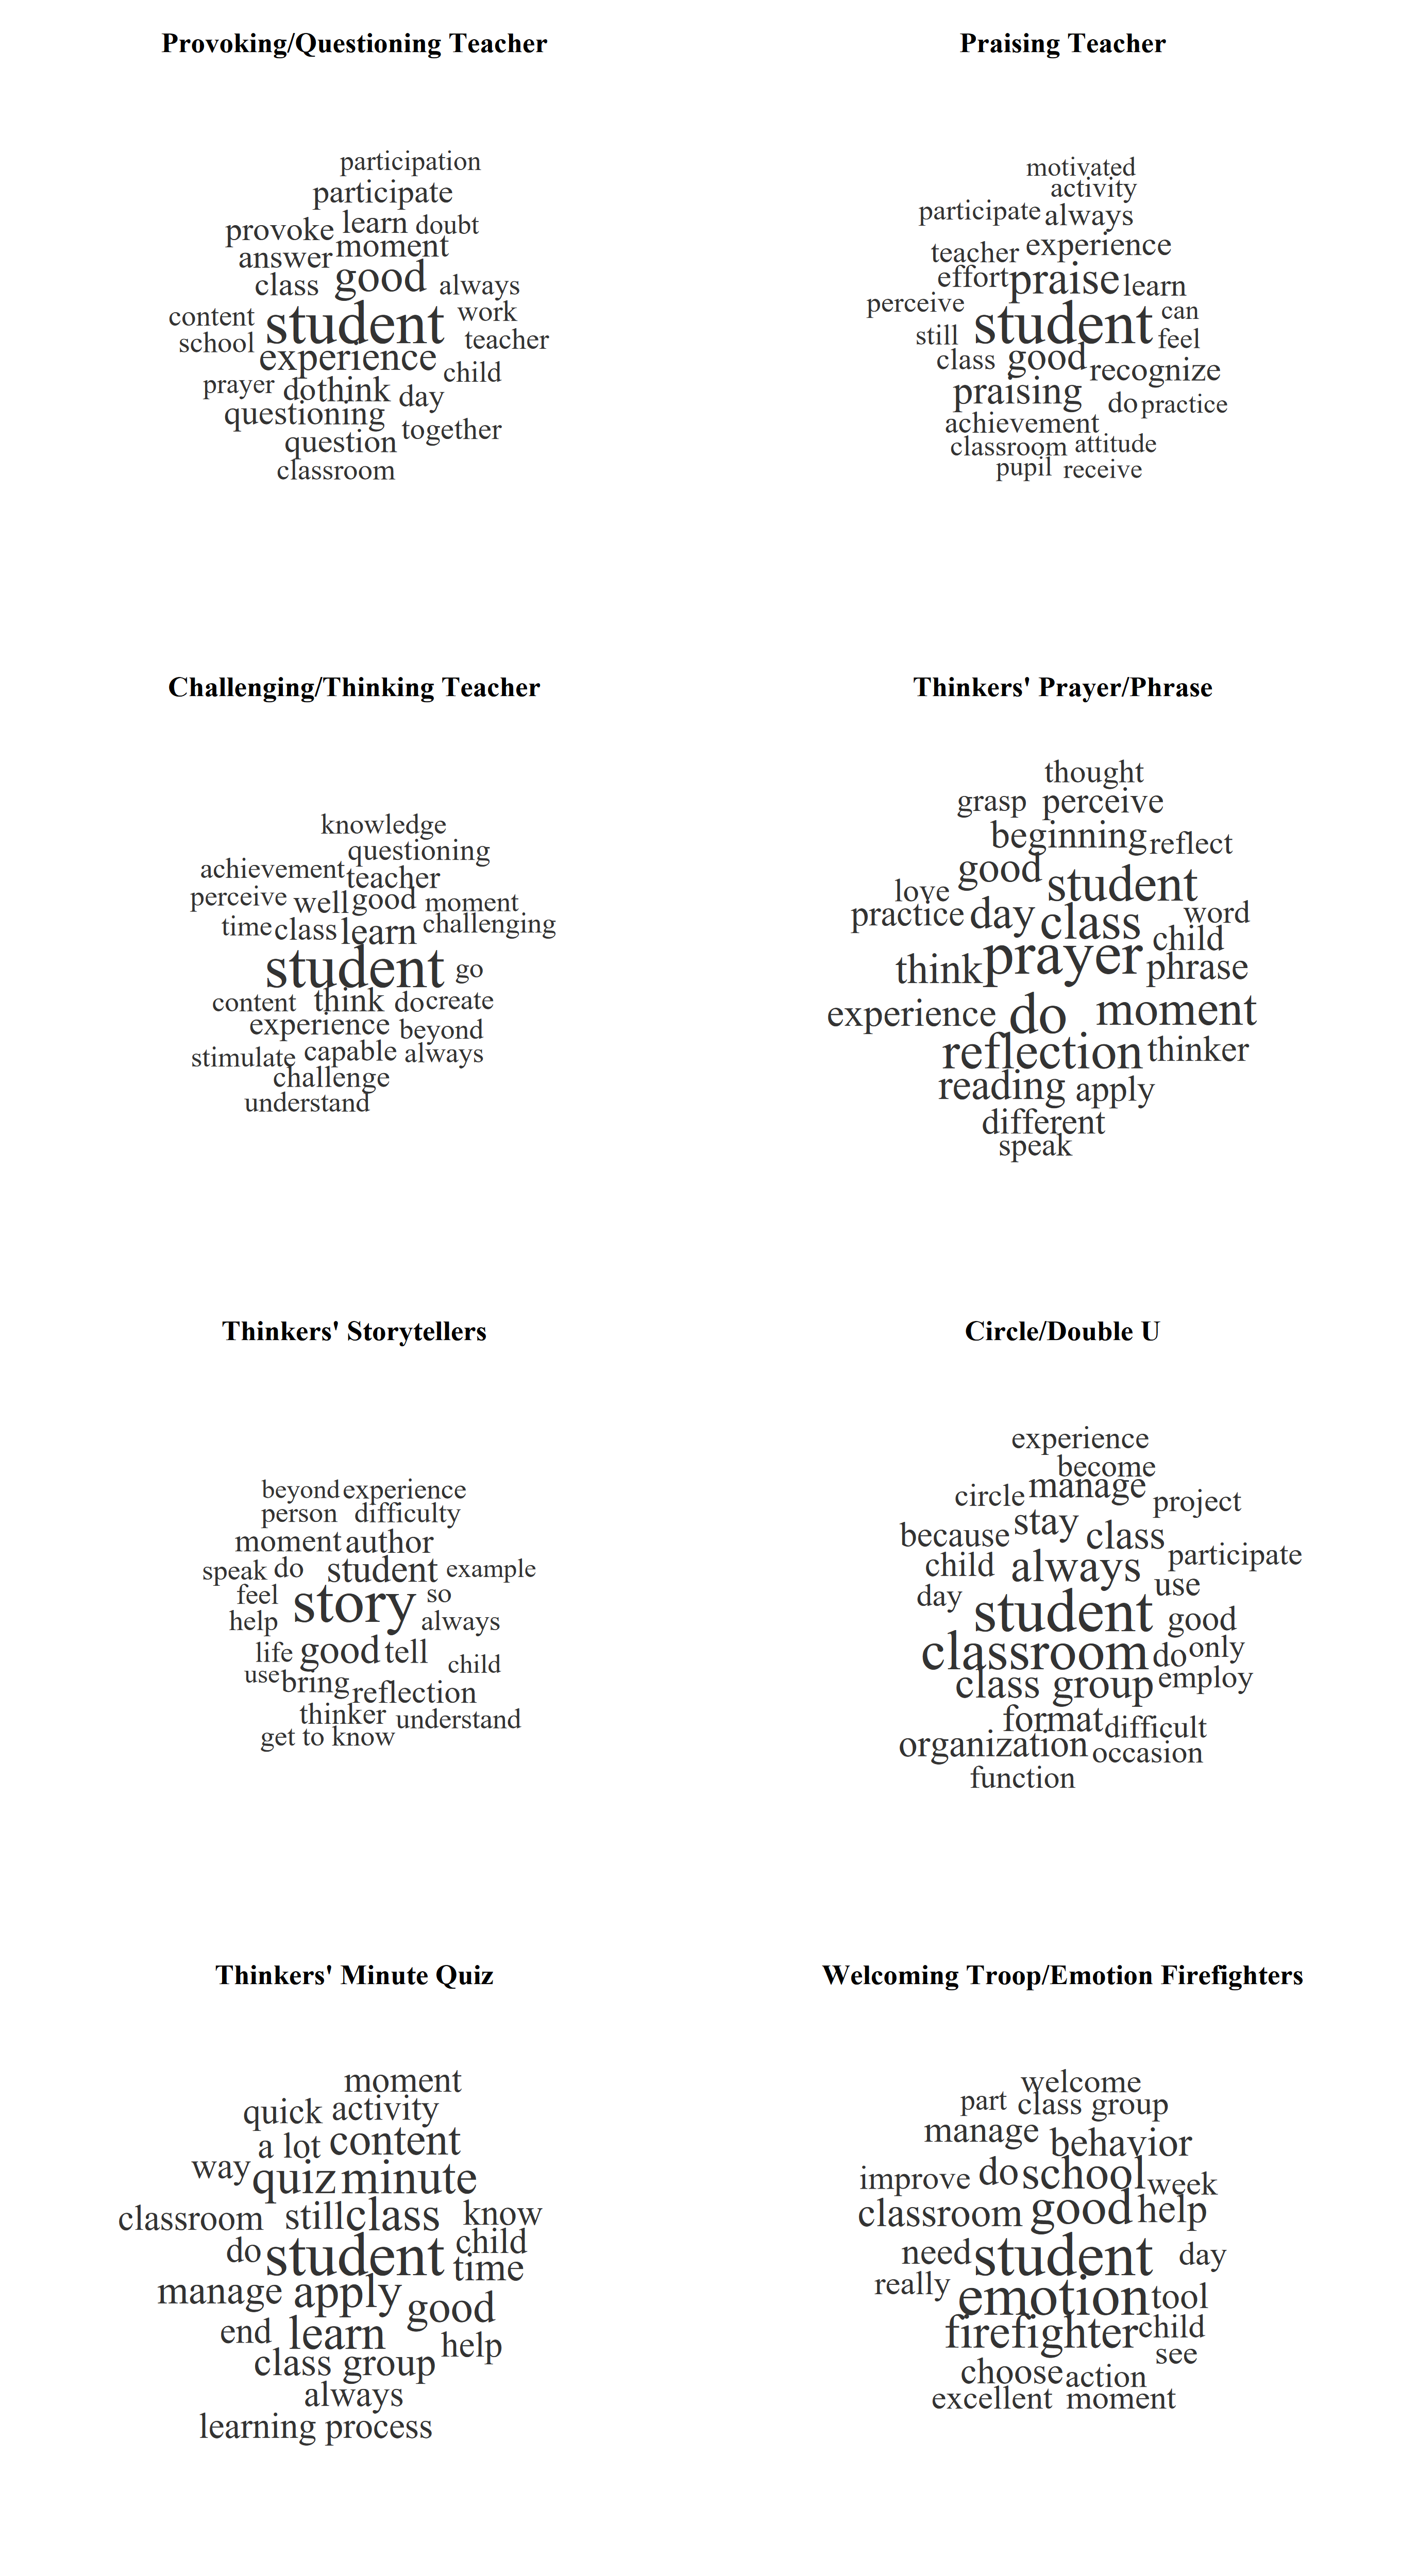

In [33]:
# one word cloud per tool; seed 2026; drawn on a temporary PNG device and shown inline
tempfile(fileext = ".png") |>
  (\(f) {png(f, width = 5.5, height = 10, units = "in", res = 500, type = "cairo")
         par(mfrow = c(4, 2), mar = c(0, 0, 2.5, 0))
         set.seed(2026)
         df |>
           filter(!is.na(mood)) |>
           select(tool, english = lemmas_en) |>
           unnest(english) |>
           count(tool, english) |>
           arrange(tool, desc(n), factor(english)) |>                                      # ties in locale alphabetical order (as base table())
           group_split(tool) |>
           walk(\(d) {wordcloud::wordcloud(d$english, d$n, max.words = 25, min.freq = 2, random.order = FALSE, rot.per = 0,
                                           colors = "grey20", family = "serif", scale = c(2.2, 0.8))
                      title(as.character(d$tool[1]), cex.main = 1, family = "serif")})
         invisible(dev.off())
         IRdisplay::display_png(file = f)})()

### 11. Reinert descending hierarchical classification (rainette): answers with >= 5 lemmas, lemmas in >= 3 answers, k = 6

In [34]:
# document-term matrix and classification; seed 2026
chd <- df |>
  filter(!is.na(resposta), lengths(lemmas) >= 5) |>
  (\(d) list(dtm = as.tokens(set_names(d$lemmas_en, str_c("a", seq_len(nrow(d))))) |> dfm(tolower = FALSE) |> dfm_trim(min_docfreq = 3),
             section = fct_drop(d$sec)))() |>
  (\(x) {set.seed(2026); c(x, res = list(rainette(x$dtm, k = 6, min_split_members = 10)))})()

  Clustering...



  Done.



In [35]:
# class sizes, characteristic terms, classes by section, class x section association (Monte Carlo p, 5000 replicates)
cutree(chd$res, k = 6) |>
  (\(g) list(documents = ndoc(chd$dtm), terms = nfeat(chd$dtm), size = table(g, useNA = "ifany"),
             characteristic_terms = rainette_stats(g, chd$dtm, n_terms = 10) |>
               map_chr(\(x) x |> filter(sign == "positive") |> slice_head(n = 10) |>
                         (\(p) str_c(p$feature, " (", round(p$chi2, 1), ")", collapse = ", "))()),
             by_section = table(class = g, section = chd$section),
             association = {set.seed(2026); chisq.test(table(g, chd$section), simulate.p.value = TRUE, B = 5000)}))()

$documents
[1] 220

$terms
[1] 297

$size
g
 1  2  3  4  5  6 
 3 58 39 90 12 18 

$characteristic_terms
[1] "chapter (268.1), workbook (95.3), quiz (46.2), minute (39.2), apply (I) (9.9), easy (7.2), end (5.6), subject (4.5)"                                           
[2] "story (57.6), reflection (17), inquiry (14.5), tell (14.5), reading (13.7), debate (11.5), phrase (11.5), small (11.5), thought (11), moment (10.7)"           
[3] "stay (44.4), tool (25.8), grasp (20.6), inside (18.1), really (18.1), day (16.1), school (15.1), for (14.4), motivated (14.4), class (10.5)"                   
[4] "classmate (11.3), knowledge (11), teacher (10.8), activity (9)"                                                                                                
[5] "firefighter (169.7), emotion (56.8), call (49.6), attention (27.9), behavior (22.5), choose (11.8), comprehension (11.8), let (11.8), week (11.8), issue (8.9)"
[6] "together (47.4), capable (37.6), give (32.3), mind (32.3), step (

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the dendextend package.
  Please report the issue at <https://github.com/talgalili/dendextend/issues>."


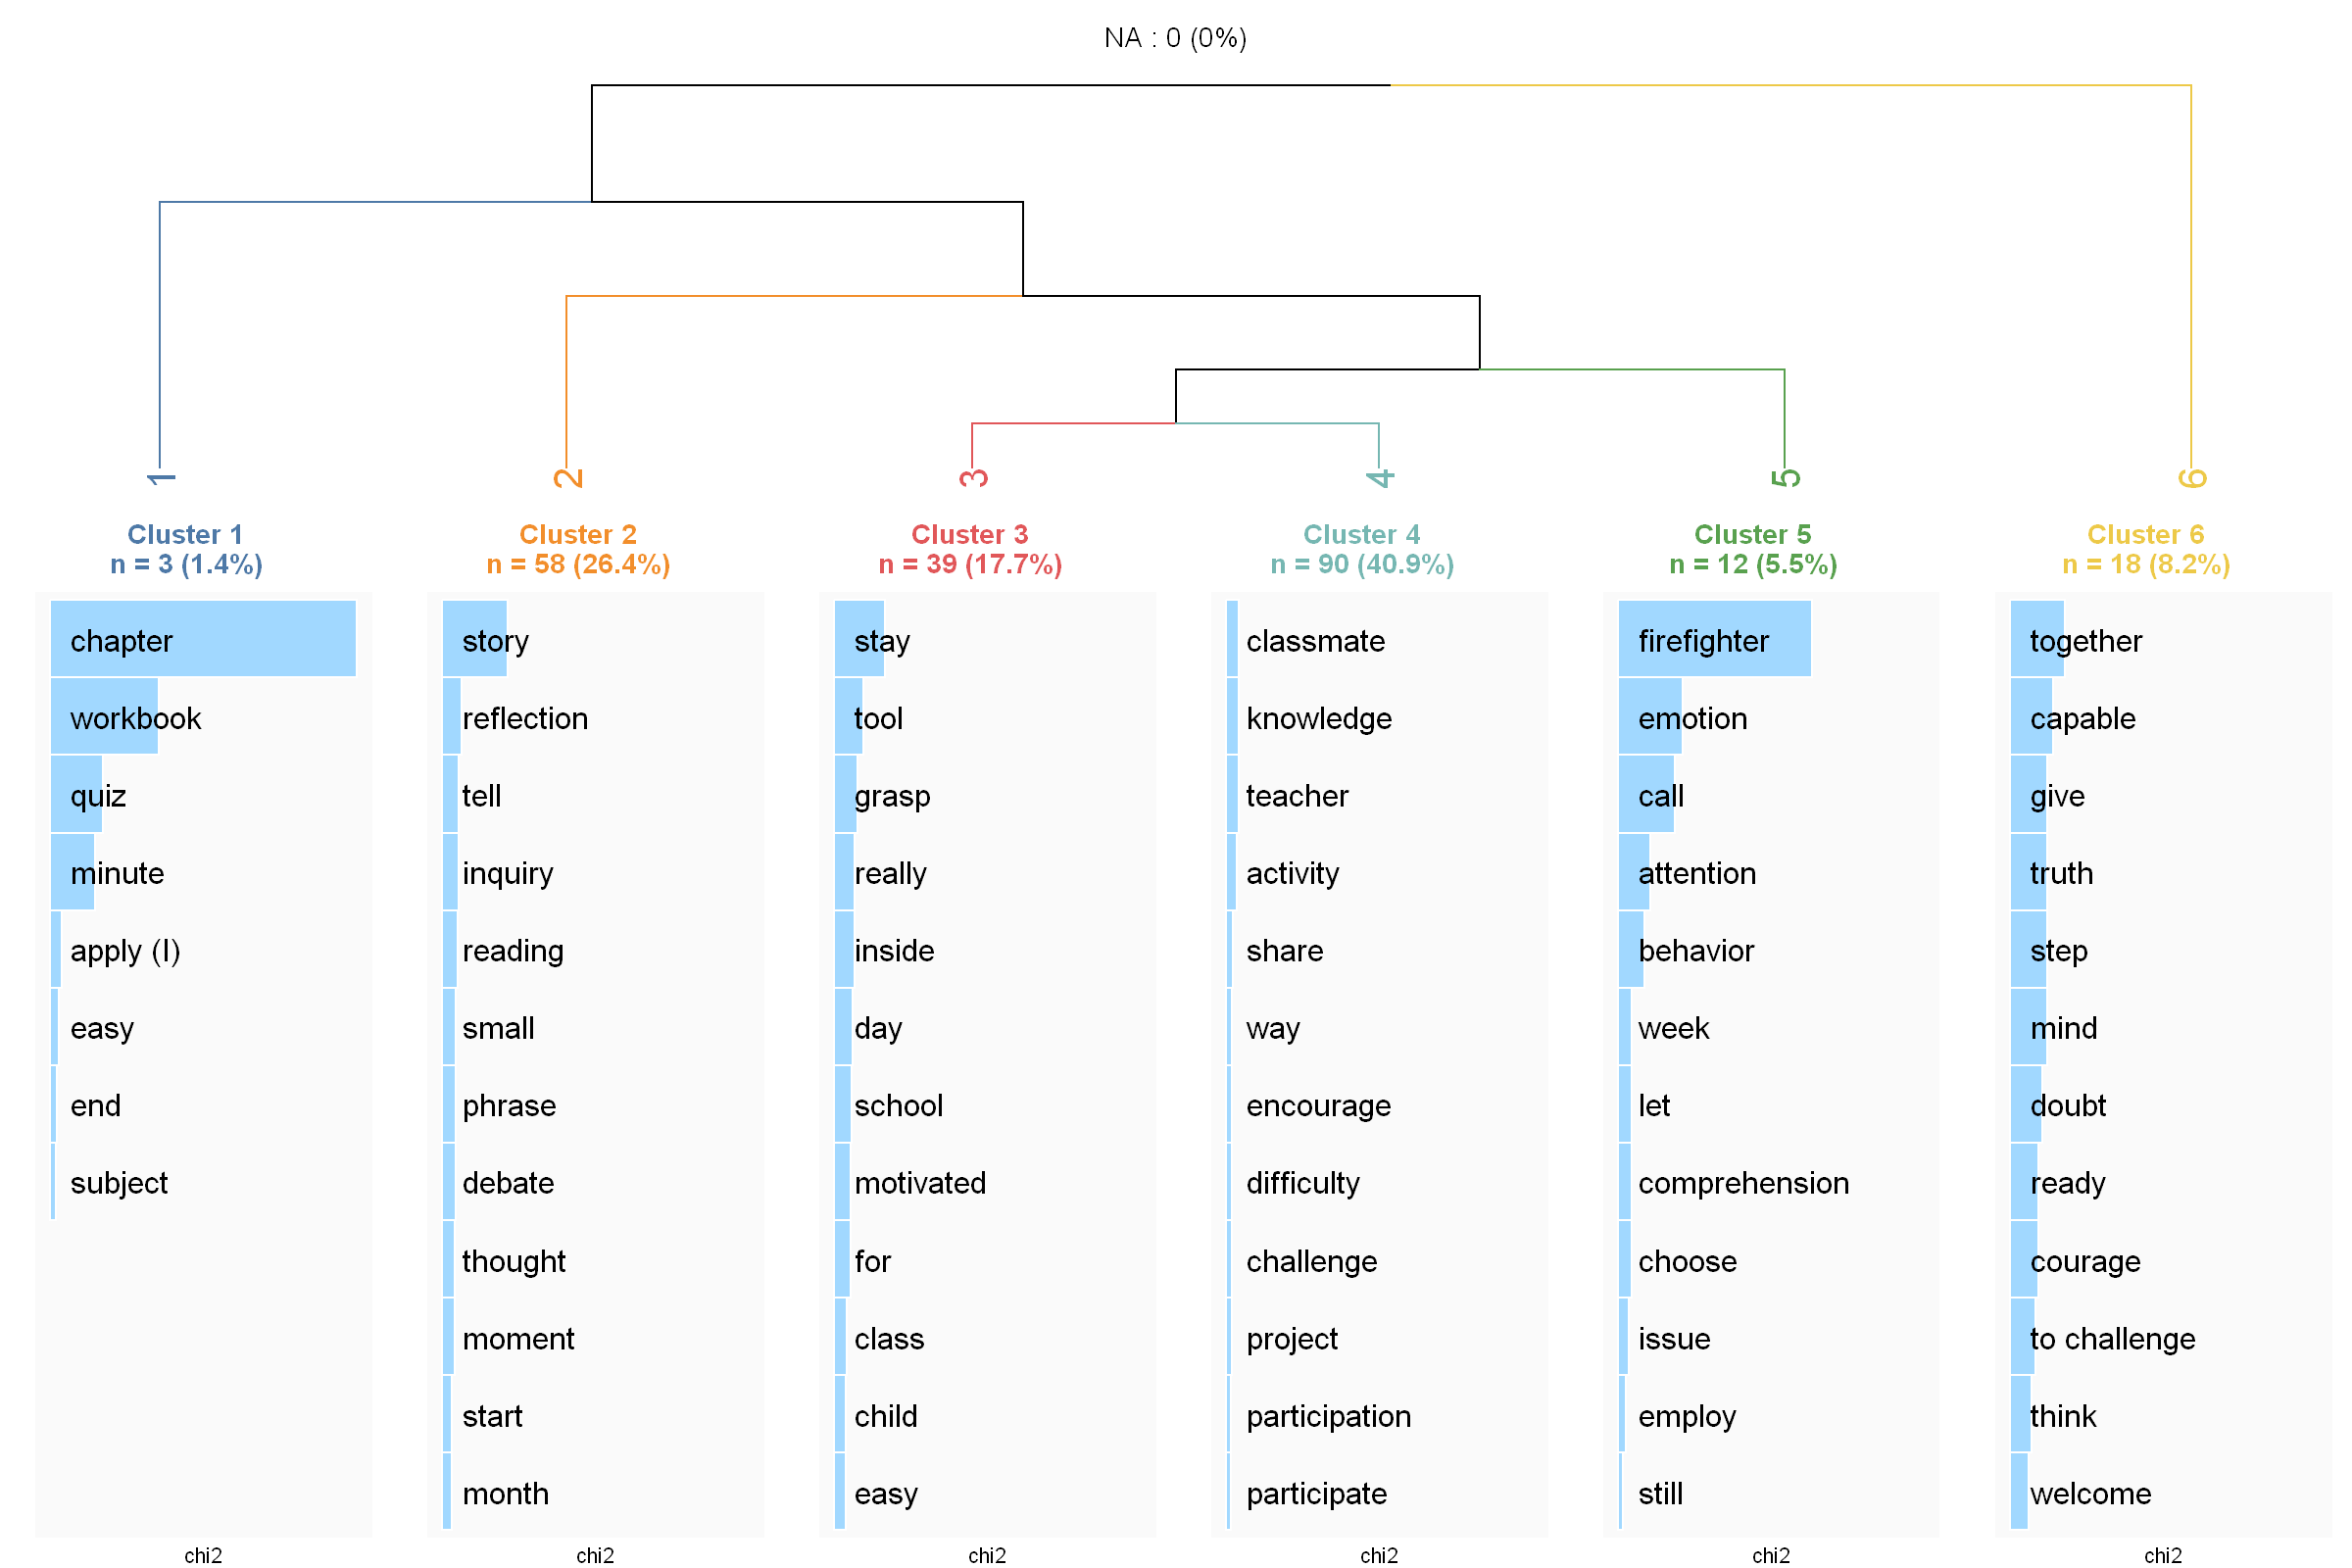

In [36]:
# dendrogram with the 12 most characteristic terms per class
options(repr.plot.width = 12, repr.plot.height = 8, repr.plot.res = 200)
rainette_plot(chd$res, chd$dtm, k = 6, n_terms = 12, free_scales = FALSE)

### 12. Second-coder subsample: random 25% of the coded answers within each tool (seed 2026)

In [37]:
# subsample ids for the second coder
set.seed(2026)
df |>
  filter(!is.na(mood)) |>
  slice_sample(prop = 0.25, by = tool) |>
  select(id_resposta, sec, tool) |>
  arrange(sec, id_resposta) |>
  (\(d) list(n = nrow(d), by_tool = as.data.frame(count(d, tool)), ids = as.data.frame(d)))()

$n
[1] 73

$by_tool
                                  tool  n
1        Provoking/Questioning Teacher 10
2                     Praising Teacher 10
3         Challenging/Thinking Teacher  9
4              Thinkers' Prayer/Phrase  9
5               Thinkers' Storytellers  8
6                      Circle/Double U  9
7                Thinkers' Minute Quiz  9
8 Welcoming Troop/Emotion Firefighters  9

$ids
   id_resposta  sec                                 tool
1            6   II        Provoking/Questioning Teacher
2           26   II        Provoking/Questioning Teacher
3           32   II        Provoking/Questioning Teacher
4           36   II        Provoking/Questioning Teacher
5           38   II        Provoking/Questioning Teacher
6           40   II        Provoking/Questioning Teacher
7           42   II        Provoking/Questioning Teacher
8           44   II        Provoking/Questioning Teacher
9           46   II        Provoking/Questioning Teacher
10          48   II        Provoking/Questioning Teacher
11           3  III                     Praising Teacher
12          14  III                     Praising Teacher
13          16  III                     Praising Teacher
14          22  III                     Praising Teacher
15          26  III                     Praising Teacher
16          38  III                     Praising Teacher
17          45  III                     Praising Teacher
18          46  III                     Praising Teacher
19          47  III                     Praising Teacher
20          53  III                     Praising Teacher
21           3   IV         Challenging/Thinking Teacher
22           9   IV         Challenging/Thinking Teacher
23          14   IV         Challenging/Thinking Teacher
24          15   IV         Challenging/Thinking Teacher
25          20   IV         Challenging/Thinking Teacher
26          44   IV         Challenging/Thinking Teacher
27          46   IV         Challenging/Thinking Teacher
28          48   IV         Challenging/Thinking Teacher
29          53   IV         Challenging/Thinking Teacher
30           6    V              Thinkers' Prayer/Phrase
31           7    V              Thinkers' Prayer/Phrase
32          11    V              Thinkers' Prayer/Phrase
33          12    V              Thinkers' Prayer/Phrase
34          28    V              Thinkers' Prayer/Phrase
35          30    V              Thinkers' Prayer/Phrase
36          39    V              Thinkers' Prayer/Phrase
37          42    V              Thinkers' Prayer/Phrase
38          45    V              Thinkers' Prayer/Phrase
39           4   VI               Thinkers' Storytellers
40          16   VI               Thinkers' Storytellers
41          28   VI               Thinkers' Storytellers
42          36   VI               Thinkers' Storytellers
43          39   VI               Thinkers' Storytellers
44          42   VI               Thinkers' Storytellers
45          47   VI               Thinkers' Storytellers
46          52   VI               Thinkers' Storytellers
47           1  VII                      Circle/Double U
48           7  VII                      Circle/Double U
49          16  VII                      Circle/Double U
50          22  VII                      Circle/Double U
51          35  VII                      Circle/Double U
52          36  VII                      Circle/Double U
53          44  VII                      Circle/Double U
54          50  VII                      Circle/Double U
55          53  VII                      Circle/Double U
56           7 VIII                Thinkers' Minute Quiz
57          11 VIII                Thinkers' Minute Quiz
58          14 VIII                Thinkers' Minute Quiz
59          28 VIII                Thinkers' Minute Quiz
60          30 VIII                Thinkers' Minute Quiz
61          32 VIII                Thinkers' Minute Quiz
62          36 VIII                Thinkers' Minute Quiz
63   